In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/03_NLP/airline_tweets.csv')
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [5]:
df['airline_sentiment'].value_counts()

,count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


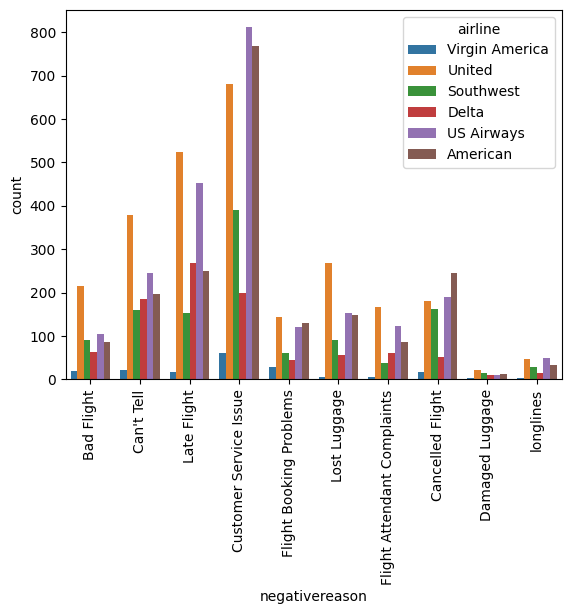

In [8]:
sns.countplot(data=df,x='negativereason',hue='airline')
plt.xticks(rotation=90)
plt.show()

# Features and Label

In [10]:
data = df[['text','airline_sentiment']]
data

,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative
...,...,...
14635,@AmericanAir thank you we got on a different f...,positive
14636,@AmericanAir leaving over 20 minutes Late Flig...,negative
14637,@AmericanAir Please bring American Airlines to...,neutral
14638,"@AmericanAir you have my money, you change my ...",negative


In [11]:
X = df['text']
y = df['airline_sentiment']

In [12]:
#Train Test split

from sklearn.model_selection import train_test_split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=50)

In [17]:
len(X_train), len(X_test)

(11712, 2928)

# Vectorization

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [19]:
tfidf = TfidfVectorizer(stop_words='english')

In [20]:
tfidf.fit(X_train)

TfidfVectorizer(stop_words='english')

In [23]:
X_train_tfidf = tfidf.transform(X_train)

In [24]:
X_test_tfidf = tfidf.transform(X_test)

* Data Leakage (Find more about it)

In [25]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()
nb.fit(X_train_tfidf,y_train)

MultinomialNB()

In [26]:
from sklearn.linear_model import LogisticRegression

log = LogisticRegression()
log.fit(X_train_tfidf,y_train)

LogisticRegression()

In [28]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier()
rfc.fit(X_train_tfidf,y_train)

RandomForestClassifier()

# Performance Evaluation

In [29]:
from sklearn.metrics import confusion_matrix, classification_report

In [30]:
def report(model):
  pred = model.predict(X_test_tfidf)
  print(classification_report(y_test,pred))
  print(confusion_matrix(y_test,pred))

In [31]:
report(model=nb)

              precision    recall  f1-score   support

    negative       0.66      0.99      0.80      1835
     neutral       0.78      0.13      0.23       610
    positive       0.95      0.14      0.25       483

    accuracy                           0.67      2928
   macro avg       0.80      0.42      0.42      2928
weighted avg       0.73      0.67      0.59      2928

[[1825   10    0]
 [ 525   81    4]
 [ 400   13   70]]


In [32]:
report(model=rfc)

              precision    recall  f1-score   support

    negative       0.78      0.92      0.84      1835
     neutral       0.58      0.38      0.46       610
    positive       0.73      0.53      0.61       483

    accuracy                           0.74      2928
   macro avg       0.70      0.61      0.64      2928
weighted avg       0.73      0.74      0.73      2928

[[1696  104   35]
 [ 322  229   59]
 [ 167   60  256]]


In [33]:
report(model=log)

              precision    recall  f1-score   support

    negative       0.80      0.92      0.86      1835
     neutral       0.60      0.45      0.52       610
    positive       0.80      0.59      0.68       483

    accuracy                           0.77      2928
   macro avg       0.73      0.66      0.68      2928
weighted avg       0.76      0.77      0.76      2928

[[1688  115   32]
 [ 294  277   39]
 [ 130   67  286]]


In [34]:
from sklearn.pipeline import Pipeline

In [35]:
pipe = Pipeline([('tfidf',TfidfVectorizer()),('log',LogisticRegression())])
pipe.fit(X,y)

Pipeline(steps=[('tfidf', TfidfVectorizer()), ('log', LogisticRegression())])

In [36]:
new_tweet = ['Good flight and excellent services']
pipe.predict(new_tweet)

array(['positive'], dtype=object)

In [37]:
new_tweet = ['Good flight but seats were uncomfortable, food was bad and Pilot did not listen to me when I called him']
pipe.predict(new_tweet)

array(['negative'], dtype=object)